In [1]:
#!pip install kaggle
#!kaggle datasets download -d mlg-ulb/creditcardfraud
#!unzip creditcardfraud.zip

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.shape

(284807, 31)

<Axes: xlabel='Class', ylabel='count'>

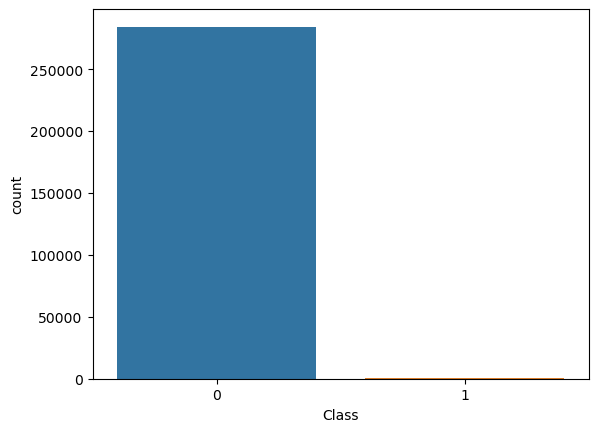

In [5]:
sns.countplot(data=df, x='Class')

In [6]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [7]:
df['Class'].value_counts(normalize=True) * 100 

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

In [8]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [9]:
df['Amount'].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

<Axes: xlabel='Class', ylabel='Amount'>

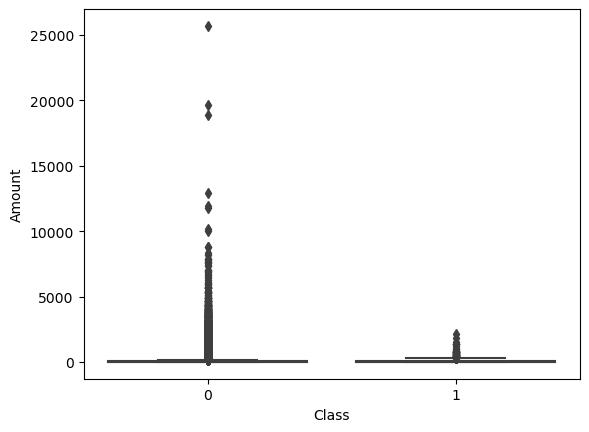

In [10]:
sns.boxplot(data=df, x='Class', y='Amount')

In [11]:
df['Time'].value_counts()

Time
163152.0    36
64947.0     26
68780.0     25
3767.0      21
3770.0      20
            ..
127750.0     1
62260.0      1
62259.0      1
127753.0     1
172792.0     1
Name: count, Length: 124592, dtype: int64

In [12]:
X = df.drop(columns=['Class'])
y = df['Class']

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42, stratify=y)

In [14]:
from sklearn.preprocessing import StandardScaler
cols=['Amount','Time']
scaler = StandardScaler()
X_train[cols]=scaler.fit_transform(X_train[cols])
X_test[cols]=scaler.transform(X_test[cols])

In [15]:
from sklearn.linear_model import LogisticRegression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X_train,y_train)
y_pred_logistic = logistic_model.predict(X_test)

In [16]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print('Accuracy:',accuracy_score(y_test,y_pred_logistic))
print(classification_report(y_test,y_pred_logistic))

Accuracy: 0.9991913775309351
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     93825
           1       0.86      0.63      0.73       162

    accuracy                           1.00     93987
   macro avg       0.93      0.81      0.86     93987
weighted avg       1.00      1.00      1.00     93987



In [17]:
print(confusion_matrix(y_test, y_pred_logistic))

[[93809    16]
 [   60   102]]


In [18]:
from sklearn.metrics import average_precision_score

logistic_model_balanced = LogisticRegression(class_weight='balanced', max_iter=1000)
logistic_model_balanced.fit(X_train, y_train)

y_pred_logistic = logistic_model_balanced.predict(X_test)
probs = logistic_model_balanced.predict_proba(X_test)[:, 1]

print(confusion_matrix(y_test, y_pred_logistic))
print(classification_report(y_test, y_pred_logistic))
print("PR-AUC:", average_precision_score(y_test, probs))

[[91814  2011]
 [   18   144]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     93825
           1       0.07      0.89      0.12       162

    accuracy                           0.98     93987
   macro avg       0.53      0.93      0.56     93987
weighted avg       1.00      0.98      0.99     93987

PR-AUC: 0.7183894405044533


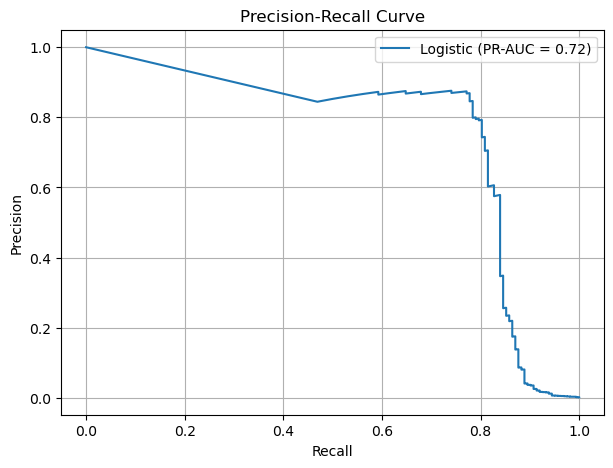

In [19]:
from sklearn.metrics import precision_recall_curve
pr_auc = average_precision_score(y_test, probs)
precision, recall, thresholds = precision_recall_curve(y_test, probs)
plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f'Logistic (PR-AUC = {pr_auc:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()

In [20]:
f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-10)

best_idx = np.argmax(f1)
print("Best threshold:", thresholds[best_idx])
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])
print("F1:", f1[best_idx])

Best threshold: 0.9999999866862956
Precision: 0.8689655172413793
Recall: 0.7777777777777778
F1: 0.8208469054876126


In [21]:
final_threshold = thresholds[best_idx]
y_pred_final = (probs>=final_threshold).astype(int)
y_pred_final

array([0, 0, 0, ..., 0, 0, 0])

In [22]:
print(confusion_matrix(y_test, y_pred_final))
print(classification_report(y_test, y_pred_final))

[[93806    19]
 [   36   126]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     93825
           1       0.87      0.78      0.82       162

    accuracy                           1.00     93987
   macro avg       0.93      0.89      0.91     93987
weighted avg       1.00      1.00      1.00     93987



In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [24]:
X_train[cols]=scaler.fit_transform(X_train[cols])
X_test[cols]=scaler.transform(X_test[cols])
X_val[cols]=scaler.transform(X_val[cols])

In [25]:
logistic_model = LogisticRegression(class_weight='balanced', max_iter=1000)
logistic_model.fit(X_train,y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [26]:
probs = logistic_model_balanced.predict_proba(X_val)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_val, probs)
f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-10)

best_idx = np.argmax(f1)
print("Best threshold:", thresholds[best_idx])
print("Precision:", precision[best_idx])
print("Recall:", recall[best_idx])
print("F1:", f1[best_idx])

Best threshold: 0.99999998667939
Precision: 0.8648648648648649
Recall: 0.7804878048780488
F1: 0.820512820462952


In [27]:
final_threshold = thresholds[best_idx]
test_probs = logistic_model_balanced.predict_proba(X_test)[:, 1]

y_pred_final = (test_probs>=final_threshold).astype(int)
print(classification_report(y_test, y_pred_final))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.85      0.82      0.83        98

    accuracy                           1.00     56962
   macro avg       0.93      0.91      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [28]:
from sklearn.ensemble import RandomForestClassifier
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
random_forest_model = RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', random_state=42)
random_forest_model.fit(X_train,y_train)

RandomForestClassifier(class_weight='balanced_subsample', n_estimators=200,
                       random_state=42)

In [61]:
probs = random_forest_model.predict_proba(X_test)[:,1]
ap_score = average_precision_score(y_test, probs)

print(f"Average Precision-Recall Score: {ap_score:.4f}")

Average Precision-Recall Score: 0.8591


In [63]:
!pip install imbalanced-learn

Looking in indexes: https://artifact.intuit.com/artifactory/api/pypi/pypi-intuit/simple


In [65]:
from imblearn.over_sampling import SMOTE
from collections import Counter

print("Before:", Counter(y_train))

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("After: ", Counter(y_train_sm))

Before: Counter({0: 227451, 1: 394})
After:  Counter({0: 227451, 1: 227451})


In [67]:
log_sm = LogisticRegression(max_iter=1000)
log_sm.fit(X_train_sm, y_train_sm)

LogisticRegression(max_iter=1000)

In [69]:
sm_probs = log_sm.predict_proba(X_test)[:, 1]
y_pred_sm = log_sm.predict(X_test)

print(confusion_matrix(y_test, y_pred_sm))
print(classification_report(y_test, y_pred_sm))
print("PR-AUC:", average_precision_score(y_test, sm_probs))

[[55916   948]
 [    9    89]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.09      0.91      0.16        98

    accuracy                           0.98     56962
   macro avg       0.54      0.95      0.57     56962
weighted avg       1.00      0.98      0.99     56962

PR-AUC: 0.7018320626273888
